正在生成输入 odd 猫态 (alpha=1.6)...
正在执行 m=1, n=1, g=1.06 的催化操作...
正在计算并绘制 Wigner 函数...


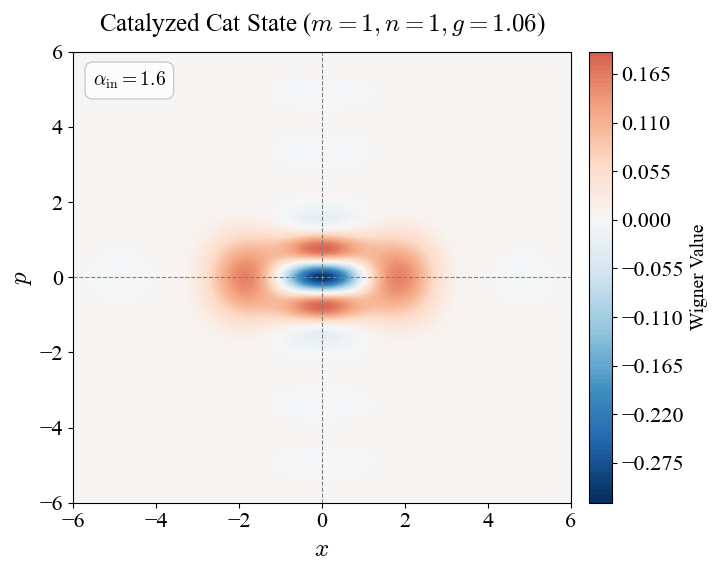

✅ 绘图完成！


In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from qutip import *
from matplotlib import rcParams
from matplotlib.colors import TwoSlopeNorm

# ========== 1. 样式配置 ==========
plt.style.use('seaborn-v0_8-muted')
rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm',
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 18,
})

# ========= 2. 核心参数设置 =========
N_DIM = 60           # 希尔伯特空间截断维度
M_VAL = 1           # 减光子阶数 m
N_VAL = 1            # 加光子阶数 n
G_VAL = 1.06        # 催化参数 g

ALPHA_IN = 1.6     # 输入猫态的初始振幅 alpha
CAT_TYPE = 'odd'    # 输入猫态的类型 ('even' 偶猫态, 'odd' 奇猫态)

X_MAX = 6.0          # 相空间画图范围 (-X_MAX 到 X_MAX)
GRID_PTS = 200       # Wigner 图分辨率

# ========= 3. 核心计算函数 =========
def generate_input_cat(dim, alpha, cat_type='even'):
    """生成初始的标准薛定谔猫态"""
    if cat_type == 'even':
        cat = coherent(dim, alpha) + coherent(dim, -alpha)
    else:
        cat = coherent(dim, alpha) - coherent(dim, -alpha)
    return cat.unit()

def generate_catalyzed_state(m, n, g, phi_in, dim):
    """
    精确执行 (m, n) 阶 g-催化操作
    """
    if g <= 1.0:
        return None
        
    G = np.sqrt(1 - 1 / (g**2)) 
    
    # 构造基础算符
    a_op = destroy(dim)
    adag = a_op.dag()
    g_op = Qobj(np.diag([g**(-j) for j in range(dim)]))
    
    psi_out = basis(dim, 0) * 0.0
    
    for k in range(m + 1):
        # 物理约束：需要保证加光子的指数不为负
        if n - m + k < 0: 
            continue
            
        # 精确系数计算 (遵循你的底层展开公式)
        num = ((-1)**(n - m + k)) * (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den = (g**(m - k + 1)) * math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = num / den
        
        # 算符作用序列: (a_dag)^(n-m+k) * g^(-n) * (a)^k |phi_in>
        psi_out += coef * (adag**(n - m + k)) * g_op * (a_op**k) * phi_in
        
    norm = psi_out.norm()
    if norm < 1e-15:
        return None
    return psi_out.unit()

# ========= 4. 态生成与 Wigner 画图 =========
print(f"正在生成输入 {CAT_TYPE} 猫态 (alpha={ALPHA_IN})...")
psi_initial = generate_input_cat(N_DIM, ALPHA_IN, CAT_TYPE)

print(f"正在执行 m={M_VAL}, n={N_VAL}, g={G_VAL} 的催化操作...")
psi_output = generate_catalyzed_state(M_VAL, N_VAL, G_VAL, psi_initial, N_DIM)

print("正在计算并绘制 Wigner 函数...")
xvec = np.linspace(-X_MAX, X_MAX, GRID_PTS)
pvec = xvec.copy()

# 计算输出态的 Wigner 矩阵
W_out = wigner(psi_output, xvec, pvec)

# 画图
fig, ax = plt.subplots(figsize=(7.5, 6))

# 使用 TwoSlopeNorm 保证 0 值严格对应白色，正值为红，负值为蓝
w_max = np.max(np.abs(W_out))
norm = TwoSlopeNorm(vmin=-w_max, vcenter=0, vmax=w_max)

cf = ax.contourf(xvec, pvec, W_out, 100, cmap='RdBu_r', norm=norm)
cbar = fig.colorbar(cf, ax=ax, pad=0.03)
cbar.set_label('Wigner Value', fontsize=14)

# 辅助参考线
ax.axhline(0, color='grey', lw=0.8, ls='--')
ax.axvline(0, color='grey', lw=0.8, ls='--')

ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$p$')
ax.set_title(rf'Catalyzed Cat State ($m={M_VAL}, n={N_VAL}, g={G_VAL}$)', fontsize=18, pad=15)

# 在左上角标注输入参数
ax.text(0.04, 0.96, fr'$\alpha_{{\mathrm{{in}}}} = {ALPHA_IN}$', 
        transform=ax.transAxes, fontsize=14, va='top', ha='left',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='silver'))

plt.tight_layout()
plt.savefig(f'wigner_m{M_VAL}_n{N_VAL}_cat.png', dpi=200, bbox_inches='tight')
plt.show()

print("✅ 绘图完成！")

🚀 启动并行架构: 物理过程 [m=1, n=1]
🔄 宇称机制激活: Odd Cat ➔ 匹配 Odd Cat

  正在计算 Case: m=3, n=2, g=1.05
    α_in   α_tgt   amp_η        F        r
  ------  ------  ------  -------  -------
   0.500   0.965   1.930 ▲   1.0000    0.094
   0.525   1.014   1.931 ▲   1.0000    0.104
   0.551   1.064   1.932 ▲   1.0000    0.114
   0.576   1.114   1.934 ▲   1.0000    0.124
   0.601   1.164   1.935 ▲   1.0000    0.135
   0.627   1.214   1.937 ▲   0.9999    0.146
   0.652   1.264   1.939 ▲   0.9999    0.158
   0.677   1.314   1.940 ▲   0.9999    0.170
   0.703   1.364   1.942 ▲   0.9998    0.182
   0.728   1.415   1.944 ▲   0.9997    0.194
   0.753   1.465   1.945 ▲   0.9996    0.207
   0.778   1.515   1.947 ▲   0.9995    0.219
   0.804   1.565   1.947 ▲   0.9993    0.232
   0.829   1.615   1.948 ▲   0.9990    0.244
   0.854   1.664   1.947 ▲   0.9987    0.257
   0.880   1.712   1.946 ▲   0.9983    0.269
   0.905   1.760   1.944 ▲   0.9978    0.281
   0.930   1.806   1.941 ▲   0.9971    0.292
   0.956   1.851

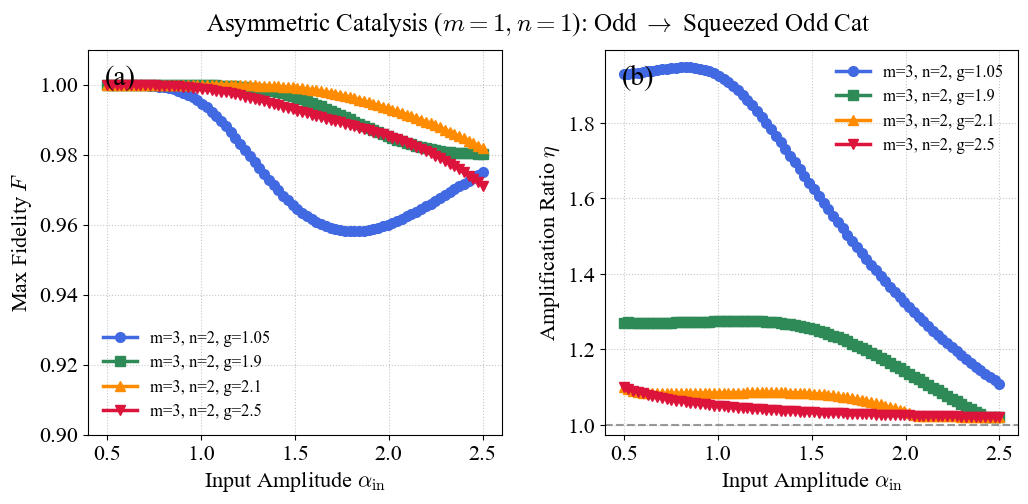

In [3]:
import numpy as np
import math
import scipy.linalg as la
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed
import time

# ============================================================
#  图表样式配置
# ============================================================
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用全局参数 (专攻 m=3, n=2)
# ============================================================
M_VAL              = 1
N_VAL              = 1

INPUT_CAT_TYPE     = "odd"    # ★ 输入为偶猫态
TARGET_CAT_TYPE    = "odd"     # ★ 输出宇称翻转，目标必须为奇猫态

N_DIM              = 60
ALPHA_IN_MIN       = 0.5
ALPHA_IN_MAX       = 2.5
ALPHA_IN_NPTS      = 80
RESTART_SEEDS      = [42, 123, 7]

DE_MAXITER         = 100
DE_POPSIZE         = 15
N_WORKERS          = -1        # 火力全开

# ============================================================
#  定义需要横向比较的不同 g 值 Case
# ============================================================
cases = [
    {'label': 'm=3, n=2, g=1.05', 'g': 1.6, 'at_offset': 3.5},
    {'label': 'm=3, n=2, g=1.9', 'g': 1.9, 'at_offset': 3.5},
    {'label': 'm=3, n=2, g=2.1', 'g': 2.1, 'at_offset': 3.5},
    {'label': 'm=3, n=2, g=2.5', 'g': 2.5, 'at_offset': 3.5}
]

# ============================================================
#  纯 Numpy 极速量子态生成引擎
# ============================================================
def get_coherent_np(dim, alpha):
    vec = np.zeros(dim, dtype=complex)
    vec[0] = 1.0
    for i in range(1, dim):
        vec[i] = vec[i-1] * alpha / math.sqrt(i)
    vec *= math.exp(-0.5 * alpha**2)
    return vec

def get_cat_state_np(dim, alpha, cat_type):
    ap = get_coherent_np(dim, alpha)
    am = get_coherent_np(dim, -alpha)
    vec = ap + am if cat_type == "even" else ap - am
    norm = np.linalg.norm(vec)
    return vec / norm if norm > 1e-15 else vec

def generate_catalyzed_state_np(m, n, g, phi_in, dim):
    """通用的 (m,n) 阶催化态极速生成"""
    if g <= 1.0: return None
    
    G = np.sqrt(1 - 1 / (g**2))
    a_op = np.diag(np.sqrt(np.arange(1, dim)), k=1)
    adag_op = a_op.T
    g_diag = g ** (-np.arange(dim, dtype=float))
    
    psi_out = np.zeros(dim, dtype=complex)
    fact_n, fact_m = math.factorial(n), math.factorial(m)
    
    for k in range(m + 1):
        if n - m + k < 0: continue # 物理拦截：不允许产生负光子
        
        num = ((-1)**(n - m + k)) * (G**(n - m + 2 * k)) * math.sqrt(fact_n * fact_m)
        den = (g**(m - k + 1)) * math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = num / den
        
        term = phi_in.copy()
        for _ in range(k): term = a_op @ term
        term = g_diag * term
        for _ in range(n - m + k): term = adag_op @ term
        
        psi_out += coef * term
        
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else None

# ============================================================
#  针对单一 alpha_in 的并行优化逻辑
# ============================================================
def optimize_one(alpha_in, case, N_dim, restart_seeds, maxiter, popsize):
    g_val = case['g']
    
    # 1. 生成准确的输出催化态
    phi_in = get_cat_state_np(N_dim, alpha_in, INPUT_CAT_TYPE)
    psi_out = generate_catalyzed_state_np(M_VAL, N_VAL, g_val, phi_in, N_dim)
    if psi_out is None:
        return float(alpha_in), 0.0, float(alpha_in), 0.0
        
    # 2. 预计算挤压生成元
    a_op = np.diag(np.sqrt(np.arange(1, N_dim)), k=1)
    S_gen = 0.5 * (a_op @ a_op - a_op.T @ a_op.T)

    # 3. 目标函数: [alpha_tgt, r] -> 寻找最完美的压缩奇猫态
    def cost(x):
        alpha_target, r_val = x
        try:
            cat_tgt = get_cat_state_np(N_dim, alpha_target, TARGET_CAT_TYPE)
            psi_tgt = la.expm(r_val * S_gen) @ cat_tgt
            psi_tgt /= np.linalg.norm(psi_tgt)
            return -abs(np.vdot(psi_out, psi_tgt))**2
        except Exception:
            return 1.0

    bounds = [(alpha_in + 0.05, alpha_in + case['at_offset']), (-1.5, 1.5)]
    
    best_F = -1.0
    best_x = None
    
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds, strategy='best1bin',
            maxiter=maxiter, popsize=popsize,
            seed=seed, tol=1e-6, disp=False
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    return float(alpha_in), best_F, float(best_x[0]), float(best_x[1])

# ============================================================
#  主程序调度与绘图
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    all_results = {}
    start_time = time.time()

    print(f"🚀 启动并行架构: 物理过程 [m={M_VAL}, n={N_VAL}]")
    print(f"🔄 宇称机制激活: {INPUT_CAT_TYPE.capitalize()} Cat ➔ 匹配 {TARGET_CAT_TYPE.capitalize()} Cat")
    
    for case in cases:
        label = case['label']
        print(f"\n{'='*65}")
        print(f"  正在计算 Case: {label}")
        print(f"{'='*65}")

        raw = Parallel(n_jobs=N_WORKERS, backend='loky')(
            delayed(optimize_one)(ai, case, N_DIM, RESTART_SEEDS, DE_MAXITER, DE_POPSIZE) 
            for ai in alpha_in_arr
        )

        raw.sort(key=lambda r: r[0])
        all_results[label] = raw

        print(f"  {'α_in':>6}  {'α_tgt':>6}  {'amp_η':>6}  {'F':>7}  {'r':>7}")
        print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*7}")
        for r in raw:
            ai, F, at, rv = r
            flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
            print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:7.3f}")

    print(f"\n✅ 所有模拟计算完成！总耗时: {time.time() - start_time:.2f} 秒")

    # ========================================================
    #  精美双子图绘制
    # ========================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    fig.subplots_adjust(wspace=0.25)

    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']

    for (label, data), color, marker in zip(all_results.items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax1.plot(alpha_vals, fids, marker=marker, color=color, lw=2.5, ms=7, label=label)
        ax2.plot(alpha_vals, amps, marker=marker, color=color, lw=2.5, ms=7, label=label)

    # 左图：保真度
    ax1.set_xlabel(r'Input Amplitude $\alpha_{\mathrm{in}}$', fontsize=16)
    ax1.set_ylabel(r'Max Fidelity $F$', fontsize=16)
    ax1.set_ylim(0.90, 1.01) # m!=n 时的畸变较大，保真度轴稍微拉宽一点
    ax1.grid(True, ls=':', alpha=0.7)
    ax1.legend(fontsize=12, frameon=False)
    ax1.text(0.04, 0.96, '(a)', transform=ax1.transAxes, fontsize=20, va='top')

    # 右图：放大率
    ax2.axhline(1.0, color='grey', ls='--', lw=1.5, alpha=0.8)
    ax2.set_xlabel(r'Input Amplitude $\alpha_{\mathrm{in}}$', fontsize=16)
    ax2.set_ylabel(r'Amplification Ratio $\eta$', fontsize=16)
    ax2.legend(fontsize=12, frameon=False)
    ax2.grid(True, ls=':', alpha=0.7)
    ax2.text(0.04, 0.96, '(b)', transform=ax2.transAxes, fontsize=20, va='top')

    fig.suptitle(rf'Asymmetric Catalysis ($m={M_VAL}, n={N_VAL}$): {INPUT_CAT_TYPE.capitalize()} $\rightarrow$ Squeezed {TARGET_CAT_TYPE.capitalize()} Cat', 
                 fontsize=18, y=0.96)
    
    plt.savefig(f'catalysis_m{M_VAL}_n{N_VAL}_comparison.png', bbox_inches='tight', dpi=200)
    plt.show()

if __name__ == '__main__':
    main()

🚀 启动并行架构: 物理过程 [m=1, n=2]
🔄 优化变量升级: [g, α_tgt, r]
🔄 宇称机制激活: Odd Cat ➔ 匹配 Even Cat

  正在计算全域最优 g 值参数...
    α_in   opt_g   α_tgt   amp_η        F        r
  ------  ------  ------  -------  -------  -------
   0.500   1.792   2.795   5.591 ▲   0.9480    0.536
   0.605   1.821   2.790   4.609 ▲   0.9492    0.528
   0.711   1.855   2.785   3.919 ▲   0.9505    0.520
   0.816   1.895   2.780   3.407 ▲   0.9518    0.512
   0.921   1.941   2.775   3.013 ▲   0.9532    0.503
   1.026   1.993   2.772   2.701 ▲   0.9546    0.495
   1.132   2.049   2.770   2.448 ▲   0.9559    0.487
   1.237   2.110   2.769   2.238 ▲   0.9571    0.479
   1.342   2.176   2.768   2.063 ▲   0.9582    0.473
   1.447   2.245   2.769   1.913 ▲   0.9593    0.466
   1.553   2.317   2.769   1.784 ▲   0.9603    0.461
   1.658   2.393   2.771   1.671 ▲   0.9611    0.456
   1.763   1.050   2.561   1.453 ▲   0.9847    0.226
   1.868   1.050   2.625   1.405 ▲   0.9886    0.214
   1.974   1.050   2.692   1.364 ▲   0.9915    0.204

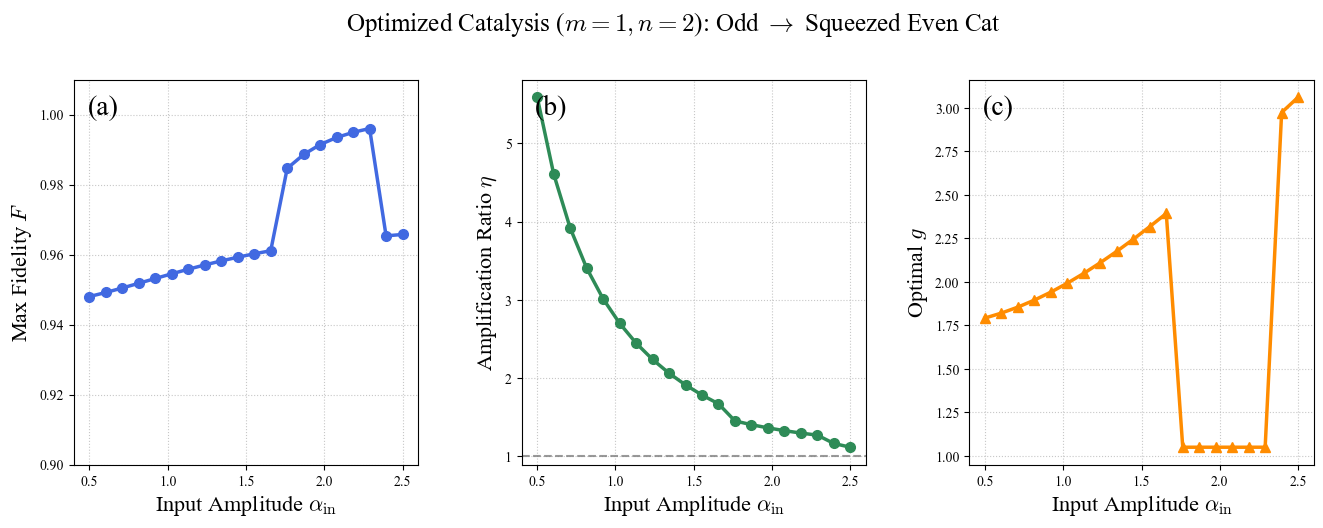

In [43]:
import numpy as np
import math
import scipy.linalg as la
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed
import time

# ============================================================
#  图表样式配置
# ============================================================
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用全局参数 (专攻 m=3, n=2)
# ============================================================
M_VAL              = 1 # 注意：你的原代码写的是 1，按你实际需求可改为 3
N_VAL              = 2

INPUT_CAT_TYPE     = "odd"    # ★ 输入为偶猫态 (注：变量名写的是odd，请确认物理意图)
TARGET_CAT_TYPE    = "even"   # ★ 输出宇称翻转，目标必须为奇猫态

N_DIM              = 60
ALPHA_IN_MIN       = 0.5
ALPHA_IN_MAX       = 2.5
ALPHA_IN_NPTS      = 20
RESTART_SEEDS      = [42, 123, 7]

DE_MAXITER         = 100
DE_POPSIZE         = 15
N_WORKERS          = -1        # 火力全开

# ============================================================
#  纯 Numpy 极速量子态生成引擎
# ============================================================
def get_coherent_np(dim, alpha):
    vec = np.zeros(dim, dtype=complex)
    vec[0] = 1.0
    for i in range(1, dim):
        vec[i] = vec[i-1] * alpha / math.sqrt(i)
    vec *= math.exp(-0.5 * alpha**2)
    return vec

def get_cat_state_np(dim, alpha, cat_type):
    ap = get_coherent_np(dim, alpha)
    am = get_coherent_np(dim, -alpha)
    vec = ap + am if cat_type == "even" else ap - am
    norm = np.linalg.norm(vec)
    return vec / norm if norm > 1e-15 else vec

def generate_catalyzed_state_np(m, n, g, phi_in, dim):
    """通用的 (m,n) 阶催化态极速生成"""
    if g <= 1.0: return None
    
    G = np.sqrt(1 - 1 / (g**2))
    a_op = np.diag(np.sqrt(np.arange(1, dim)), k=1)
    adag_op = a_op.T
    g_diag = g ** (-np.arange(dim, dtype=float))
    
    psi_out = np.zeros(dim, dtype=complex)
    fact_n, fact_m = math.factorial(n), math.factorial(m)
    
    for k in range(m + 1):
        if n - m + k < 0: continue # 物理拦截：不允许产生负光子
        
        num = ((-1)**(n - m + k)) * (G**(n - m + 2 * k)) * math.sqrt(fact_n * fact_m)
        den = (g**(m - k + 1)) * math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = num / den
        
        term = phi_in.copy()
        for _ in range(k): term = a_op @ term
        term = g_diag * term
        for _ in range(n - m + k): term = adag_op @ term
        
        psi_out += coef * term
        
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else None

# ============================================================
#  针对单一 alpha_in 的并行优化逻辑 (现加入 g 为优化变量)
# ============================================================
def optimize_one(alpha_in, N_dim, restart_seeds, maxiter, popsize):
    # 1. 生成输入猫态 (只需生成一次)
    phi_in = get_cat_state_np(N_dim, alpha_in, INPUT_CAT_TYPE)
        
    # 2. 预计算挤压生成元
    a_op = np.diag(np.sqrt(np.arange(1, N_dim)), k=1)
    S_gen = 0.5 * (a_op @ a_op - a_op.T @ a_op.T)

    # 3. 目标函数: [g_val, alpha_tgt, r_val] 
    def cost(x):
        g_val, alpha_target, r_val = x
        try:
            # 每次评估时，g 都在变，因此必须在 cost 内部重新生成 psi_out
            psi_out = generate_catalyzed_state_np(M_VAL, N_VAL, g_val, phi_in, N_dim)
            if psi_out is None:
                return 1.0
                
            cat_tgt = get_cat_state_np(N_dim, alpha_target, TARGET_CAT_TYPE)
            psi_tgt = la.expm(r_val * S_gen) @ cat_tgt
            psi_tgt /= np.linalg.norm(psi_tgt)
            return -abs(np.vdot(psi_out, psi_tgt))**2
        except Exception:
            return 1.0

    # 物理边界限制：g_val > 1 (此处设定在1.05~10.0之间搜寻)，alpha_tgt 和 r 类似之前
    bounds = [(1.05, 10.0), (alpha_in + 0.05, alpha_in + 4.5), (-1.5, 1.5)]
    
    best_F = -1.0
    best_x = None
    
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds, strategy='best1bin',
            maxiter=maxiter, popsize=popsize,
            seed=seed, tol=1e-6, disp=False
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    return float(alpha_in), best_F, float(best_x[0]), float(best_x[1]), float(best_x[2])

# ============================================================
#  主程序调度与绘图
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    start_time = time.time()

    print(f"🚀 启动并行架构: 物理过程 [m={M_VAL}, n={N_VAL}]")
    print(f"🔄 优化变量升级: [g, α_tgt, r]")
    print(f"🔄 宇称机制激活: {INPUT_CAT_TYPE.capitalize()} Cat ➔ 匹配 {TARGET_CAT_TYPE.capitalize()} Cat")
    
    print(f"\n{'='*75}")
    print(f"  正在计算全域最优 g 值参数...")
    print(f"{'='*75}")

    raw = Parallel(n_jobs=N_WORKERS, backend='loky')(
        delayed(optimize_one)(ai, N_DIM, RESTART_SEEDS, DE_MAXITER, DE_POPSIZE) 
        for ai in alpha_in_arr
    )

    raw.sort(key=lambda r: r[0])

    print(f"  {'α_in':>6}  {'opt_g':>6}  {'α_tgt':>6}  {'amp_η':>6}  {'F':>7}  {'r':>7}")
    print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*7}  {'-'*7}")
    for r in raw:
        ai, F, opt_g, at, rv = r
        flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
        print(f"  {ai:6.3f}  {opt_g:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:7.3f}")

    print(f"\n✅ 所有模拟计算完成！总耗时: {time.time() - start_time:.2f} 秒")

    # ========================================================
    #  精美三子图绘制
    # ========================================================
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))
    fig.subplots_adjust(wspace=0.3)

    alpha_vals = np.array([d[0] for d in raw])
    fids       = np.array([d[1] for d in raw])
    opt_gs     = np.array([d[2] for d in raw])
    amps       = np.array([d[3] for d in raw]) / alpha_vals

    color = 'royalblue'
    marker = 'o'

    # 左图：保真度
    ax1.plot(alpha_vals, fids, marker=marker, color=color, lw=2.5, ms=7)
    ax1.set_xlabel(r'Input Amplitude $\alpha_{\mathrm{in}}$', fontsize=16)
    ax1.set_ylabel(r'Max Fidelity $F$', fontsize=16)
    ax1.set_ylim(0.90, 1.01)
    ax1.grid(True, ls=':', alpha=0.7)
    ax1.text(0.04, 0.96, '(a)', transform=ax1.transAxes, fontsize=20, va='top')

    # 中图：放大率
    ax2.plot(alpha_vals, amps, marker=marker, color='seagreen', lw=2.5, ms=7)
    ax2.axhline(1.0, color='grey', ls='--', lw=1.5, alpha=0.8)
    ax2.set_xlabel(r'Input Amplitude $\alpha_{\mathrm{in}}$', fontsize=16)
    ax2.set_ylabel(r'Amplification Ratio $\eta$', fontsize=16)
    ax2.grid(True, ls=':', alpha=0.7)
    ax2.text(0.04, 0.96, '(b)', transform=ax2.transAxes, fontsize=20, va='top')

    # 右图：最佳 g 值
    ax3.plot(alpha_vals, opt_gs, marker='^', color='darkorange', lw=2.5, ms=7)
    ax3.set_xlabel(r'Input Amplitude $\alpha_{\mathrm{in}}$', fontsize=16)
    ax3.set_ylabel(r'Optimal $g$', fontsize=16)
    ax3.grid(True, ls=':', alpha=0.7)
    ax3.text(0.04, 0.96, '(c)', transform=ax3.transAxes, fontsize=20, va='top')

    fig.suptitle(rf'Optimized Catalysis ($m={M_VAL}, n={N_VAL}$): {INPUT_CAT_TYPE.capitalize()} $\rightarrow$ Squeezed {TARGET_CAT_TYPE.capitalize()} Cat', 
                 fontsize=18, y=1.02)
    
    plt.savefig(f'catalysis_m{M_VAL}_n{N_VAL}_optimized_g.png', bbox_inches='tight', dpi=200)
    plt.show()

if __name__ == '__main__':
    main()

🚀 启动精简版并行架构: 计算 Even 和 Odd 分组数据

================ 正在计算组别: even_group ================
-> 测算 Case: m=0, n=2, g=1.01 [Input: Even]
-> 测算 Case: m=1, n=2, g=1.05 [Input: Even]
-> 测算 Case: m=3, n=2, g=1.60 [Input: Even]
-> 测算 Case: m=1, n=3, g=1.01 [Input: Even]

================ 正在计算组别: odd_group ================
-> 测算 Case: m=0, n=2, g=1.01 [Input: Odd]
-> 测算 Case: m=1, n=2, g=1.05 [Input: Odd]
-> 测算 Case: m=3, n=2, g=3.30 [Input: Odd]
-> 测算 Case: m=4, n=2, g=1.70 [Input: Odd]

✅ 模拟计算完成！总耗时: 20.36 秒


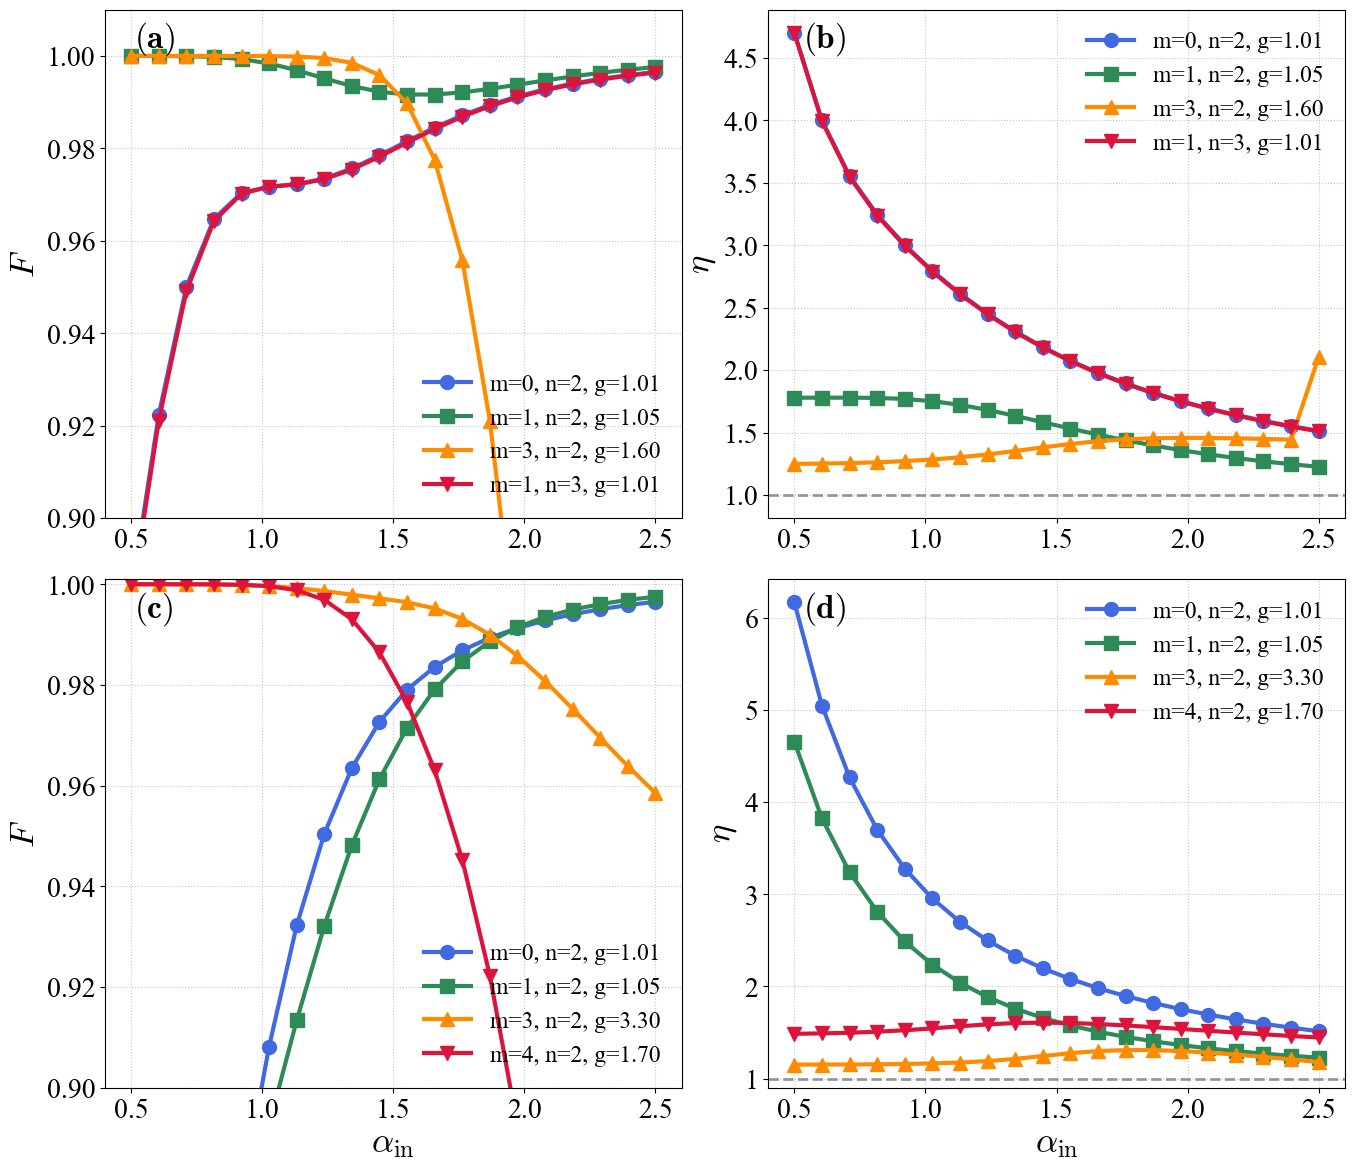

In [21]:
import numpy as np
import math
import scipy.linalg as la
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed
import time

# ============================================================
#  全局尺寸及字号设置 (统一大字号参数)
# ============================================================
FIG_SIZE = (16, 14)             # 画布整体物理尺寸 (宽, 高)
LABEL_SIZE = 25                 # 坐标轴标签大小
TICK_SIZE = 20                  # 坐标轴数字刻度大小
SUBPLOT_LABEL_SIZE = 24         # (a)(b)(c)(d) 角标字体大小
CASE_LABEL_SIZE = 17            # 图例 (m=, n=, g=) 文本大小

# ============================================================
#  图表样式配置
# ============================================================
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用全局参数
# ============================================================
N_DIM              = 60
ALPHA_IN_MIN       = 0.5
ALPHA_IN_MAX       = 2.5
ALPHA_IN_NPTS      = 20
RESTART_SEEDS      = [42, 123, 7]

DE_MAXITER         = 100
DE_POPSIZE         = 15
N_WORKERS          = -1        # 火力全开

# ============================================================
#  定义分组 Case
# ============================================================

# Even 输入组 (将绘制在图 a 和图 b)
cases_even = [
    {'label': 'm=0, n=2, g=1.01', 'm': 0, 'n': 2, 'g': 1.01, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=1, n=2, g=1.05', 'm': 1, 'n': 2, 'g': 1.05, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=3, n=2, g=1.60', 'm': 3, 'n': 2, 'g': 1.60, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=1, n=3, g=1.01', 'm': 1, 'n': 3, 'g': 1.01, 'in_cat': 'even', 'at_offset': 4.0}  
    
]

# Odd 输入组 (将绘制在图 c 和图 d)
cases_odd = [
    {'label': 'm=0, n=2, g=1.01', 'm': 0, 'n': 2, 'g': 1.01, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=1, n=2, g=1.05', 'm': 1, 'n': 2, 'g': 1.05, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=3, n=2, g=3.30', 'm': 3, 'n': 2, 'g': 3.30, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=4, n=2, g=1.70', 'm': 4, 'n': 2, 'g': 1.70, 'in_cat': 'odd', 'at_offset': 4.0}
    
]

# 整合调度字典
all_case_groups = {
    'even_group': cases_even,
    'odd_group': cases_odd
}

# ============================================================
#  纯 Numpy 极速量子态生成引擎
# ============================================================
def get_coherent_np(dim, alpha):
    vec = np.zeros(dim, dtype=complex)
    vec[0] = 1.0
    for i in range(1, dim):
        vec[i] = vec[i-1] * alpha / math.sqrt(i)
    vec *= math.exp(-0.5 * alpha**2)
    return vec

def get_cat_state_np(dim, alpha, cat_type):
    ap = get_coherent_np(dim, alpha)
    am = get_coherent_np(dim, -alpha)
    vec = ap + am if cat_type == "even" else ap - am
    norm = np.linalg.norm(vec)
    return vec / norm if norm > 1e-15 else vec

def generate_catalyzed_state_np(m, n, g, phi_in, dim):
    if g <= 1.0: return None
    
    G = np.sqrt(1 - 1 / (g**2))
    a_op = np.diag(np.sqrt(np.arange(1, dim)), k=1)
    adag_op = a_op.T
    g_diag = g ** (-np.arange(dim, dtype=float))
    
    psi_out = np.zeros(dim, dtype=complex)
    fact_n, fact_m = math.factorial(n), math.factorial(m)
    
    for k in range(m + 1):
        if n - m + k < 0: continue
        
        num = ((-1)**(n - m + k)) * (G**(n - m + 2 * k)) * math.sqrt(fact_n * fact_m)
        den = (g**(m - k + 1)) * math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = num / den
        
        term = phi_in.copy()
        for _ in range(k): term = a_op @ term
        term = g_diag * term
        for _ in range(n - m + k): term = adag_op @ term
        
        psi_out += coef * term
        
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else None

# ============================================================
#  针对单一 alpha_in 的并行优化逻辑
# ============================================================
def optimize_one(alpha_in, case, N_dim, restart_seeds, maxiter, popsize):
    m_val = case['m']
    n_val = case['n']
    g_val = case['g']
    in_cat = case['in_cat']
    
    if abs(n_val - m_val) % 2 != 0:
        tgt_cat = "odd" if in_cat == "even" else "even"
    else:
        tgt_cat = in_cat
        
    phi_in = get_cat_state_np(N_dim, alpha_in, in_cat)
    psi_out = generate_catalyzed_state_np(m_val, n_val, g_val, phi_in, N_dim)
    if psi_out is None:
        return float(alpha_in), 0.0, float(alpha_in), 0.0
        
    a_op = np.diag(np.sqrt(np.arange(1, N_dim)), k=1)
    S_gen = 0.5 * (a_op @ a_op - a_op.T @ a_op.T)

    def cost(x):
        alpha_target, r_val = x
        try:
            cat_tgt = get_cat_state_np(N_dim, alpha_target, tgt_cat)
            psi_tgt = la.expm(r_val * S_gen) @ cat_tgt
            psi_tgt /= np.linalg.norm(psi_tgt)
            return -abs(np.vdot(psi_out, psi_tgt))**2
        except Exception:
            return 1.0

    bounds = [(max(0.1, alpha_in * 0.5), alpha_in + case['at_offset']), (-1.5, 1.5)]
    
    best_F = -1.0
    best_x = None
    
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds, strategy='best1bin',
            maxiter=maxiter, popsize=popsize,
            seed=seed, tol=1e-6, disp=False
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    return float(alpha_in), best_F, float(best_x[0]), float(best_x[1])

# ============================================================
#  主程序调度与绘图
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    start_time = time.time()
    
    print(f"🚀 启动精简版并行架构: 计算 Even 和 Odd 分组数据")
    
    all_results = {'even_group': {}, 'odd_group': {}}

    for group_key, cases_list in all_case_groups.items():
        print(f"\n================ 正在计算组别: {group_key} ================")
        for case in cases_list:
            label = case['label']
            print(f"-> 测算 Case: {label} [Input: {case['in_cat'].capitalize()}]")

            raw = Parallel(n_jobs=N_WORKERS, backend='loky')(
                delayed(optimize_one)(ai, case, N_DIM, RESTART_SEEDS, DE_MAXITER, DE_POPSIZE) 
                for ai in alpha_in_arr
            )

            raw.sort(key=lambda r: r[0])
            all_results[group_key][label] = raw

    print(f"\n✅ 模拟计算完成！总耗时: {time.time() - start_time:.2f} 秒")

    # ========================================================
    #  精美四宫格绘制 (2x2 布局)
    # ========================================================
    fig, axs = plt.subplots(2, 2, figsize=FIG_SIZE)
    # 🌟 修改点：大幅缩小子图间距 (wspace水平间距, hspace垂直间距)
    fig.subplots_adjust(wspace=0.15, hspace=0.12) 

    ax_a = axs[0, 0] # 左上: (a) Even 保真度
    ax_b = axs[0, 1] # 右上: (b) Even 放大率
    ax_c = axs[1, 0] # 左下: (c) Odd 保真度
    ax_d = axs[1, 1] # 右下: (d) Odd 放大率

    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']
    
    plot_kwargs = dict(lw=3, ms=10)

    # --- 行 1：绘制 Even 组的保真度 (a) 和放大倍数 (b) ---
    for (label, data), color, marker in zip(all_results['even_group'].items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax_a.plot(alpha_vals, fids, marker=marker, color=color, label=label, **plot_kwargs)
        ax_b.plot(alpha_vals, amps, marker=marker, color=color, label=label, **plot_kwargs)

    # 样式配置 (a) - Even 保真度
    ax_a.set_ylabel(r'$F$', fontsize=LABEL_SIZE)
    ax_a.text(0.05, 0.98, r'$\mathbf{(a)}$', transform=ax_a.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_a.set_ylim(0.9, 1.01)
    ax_a.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_a.grid(True, ls=':', alpha=0.7)
    ax_a.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='best')

    # 样式配置 (b) - Even 放大率
    ax_b.axhline(1.0, color='grey', ls='--', lw=2, alpha=0.8)
    ax_b.set_ylabel(r'$\eta$', fontsize=LABEL_SIZE)
    ax_b.text(0.06, 0.98, r'$\mathbf{(b)}$', transform=ax_b.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_b.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_b.grid(True, ls=':', alpha=0.7)
    ax_b.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='best')


    # --- 行 2：绘制 Odd 组的保真度 (c) 和放大倍数 (d) ---
    for (label, data), color, marker in zip(all_results['odd_group'].items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax_c.plot(alpha_vals, fids, marker=marker, color=color, label=label, **plot_kwargs)
        ax_d.plot(alpha_vals, amps, marker=marker, color=color, label=label, **plot_kwargs)

    # 样式配置 (c) - Odd 保真度
    ax_c.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=LABEL_SIZE)
    ax_c.set_ylabel(r'$F$', fontsize=LABEL_SIZE)
    ax_c.text(0.05, 0.98, r'$\mathbf{(c)}$', transform=ax_c.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_c.set_ylim(0.9, 1.001)
    ax_c.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_c.grid(True, ls=':', alpha=0.7)
    ax_c.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='best')

    # 样式配置 (d) - Odd 放大率
    ax_d.axhline(1.0, color='grey', ls='--', lw=2, alpha=0.8)
    ax_d.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=LABEL_SIZE)
    ax_d.set_ylabel(r'$\eta$', fontsize=LABEL_SIZE)
    ax_d.text(0.06, 0.98, r'$\mathbf{(d)}$', transform=ax_d.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_d.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_d.grid(True, ls=':', alpha=0.7)
    ax_d.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='best')
    
    plt.savefig('catalysis_4grid_clean_labels.png', bbox_inches='tight', dpi=200)
    plt.show()

if __name__ == '__main__':
    main()

In [17]:
import numpy as np
import math
import scipy.linalg as la
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed
import time
from scipy.interpolate import interp1d

# ============================================================
#  通用全局参数
# ============================================================
N_DIM              = 60        # 希尔伯特空间截断维度
ALPHA_IN_MIN       = 0.5
ALPHA_IN_MAX       = 2.5
ALPHA_IN_NPTS      = 20        # 扫描点数
RESTART_SEEDS      = [42, 123, 7] # 随机种子重试，确保全局最优

DE_MAXITER         = 100
DE_POPSIZE         = 15
N_WORKERS          = -1        # 火力全开（CPU多核并行）

# ============================================================
#  定义分组 Case (Even组 与 Odd组)
# ============================================================
cases_even = [
    {'label': 'm=1, n=2, g=1.05', 'm': 1, 'n': 2, 'g': 1.05, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=1, n=3, g=1.01', 'm': 1, 'n': 3, 'g': 1.01, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=0, n=2, g=1.01', 'm': 0, 'n': 2, 'g': 1.01, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=3, n=2, g=1.60', 'm': 3, 'n': 2, 'g': 1.60, 'in_cat': 'even', 'at_offset': 4.0}
]

cases_odd = [
    {'label': 'm=0, n=2, g=1.01', 'm': 0, 'n': 2, 'g': 1.01, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=4, n=2, g=1.70', 'm': 4, 'n': 2, 'g': 1.70, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=3, n=2, g=3.30', 'm': 3, 'n': 2, 'g': 3.30, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=1, n=2, g=1.05', 'm': 1, 'n': 2, 'g': 1.05, 'in_cat': 'odd', 'at_offset': 4.0}
]

# ============================================================
#  高能物理矩阵引擎 & 预计算加速
# ============================================================
a_op = np.diag(np.sqrt(np.arange(1, N_DIM)), k=1)
S_gen = 0.5 * (a_op @ a_op - a_op.T @ a_op.T)

# 核心加速点：利用特征值分解替代矩阵指数
eigvals, eigvecs = la.eigh(1j * S_gen)

# ============================================================
#  量子态生成函数 (纯 Numpy)
# ============================================================
def get_coherent_np(dim, alpha):
    vec = np.zeros(dim, dtype=complex)
    vec[0] = 1.0
    for i in range(1, dim):
        vec[i] = vec[i-1] * alpha / math.sqrt(i)
    vec *= math.exp(-0.5 * alpha**2)
    return vec

def get_cat_state_np(dim, alpha, cat_type):
    ap = get_coherent_np(dim, alpha)
    am = get_coherent_np(dim, -alpha)
    vec = ap + am if cat_type == "even" else ap - am
    norm = np.linalg.norm(vec)
    return vec / norm if norm > 1e-15 else vec

def generate_catalyzed_state_np(m, n, g, phi_in, dim):
    if g <= 1.0: return None
    G = np.sqrt(1 - 1 / (g**2))
    a_op_l = np.diag(np.sqrt(np.arange(1, dim)), k=1)
    adag_op_l = a_op_l.T
    g_diag = g ** (-np.arange(dim, dtype=float))
    
    psi_out = np.zeros(dim, dtype=complex)
    fact_n, fact_m = math.factorial(n), math.factorial(m)
    
    for k in range(m + 1):
        if n - m + k < 0: continue
        num = ((-1)**(n - m + k)) * (G**(n - m + 2 * k)) * math.sqrt(fact_n * fact_m)
        den = (g**(m - k + 1)) * math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = num / den
        
        term = phi_in.copy()
        for _ in range(k): term = a_op_l @ term
        term = g_diag * term
        for _ in range(n - m + k): term = adag_op_l @ term
        
        psi_out += coef * term
        
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else None

# ============================================================
#  针对单一 alpha_in 的并行寻优逻辑
# ============================================================
def optimize_one(alpha_in, case):
    m_val = case['m']
    n_val = case['n']
    g_val = case['g']
    in_cat = case['in_cat']
    
    if abs(n_val - m_val) % 2 != 0:
        tgt_cat = "odd" if in_cat == "even" else "even"
    else:
        tgt_cat = in_cat
        
    phi_in = get_cat_state_np(N_DIM, alpha_in, in_cat)
    psi_out = generate_catalyzed_state_np(m_val, n_val, g_val, phi_in, N_DIM)
    if psi_out is None:
        return float(alpha_in), 0.0, float(alpha_in), 0.0
        
    bounds = [(max(0.1, alpha_in * 0.5), alpha_in + case['at_offset']), (-1.5, 1.5)]
    best_F = -1.0
    best_x = None
    
    for seed in RESTART_SEEDS:
        def cost(x):
            alpha_target, r_val = x
            try:
                cat_tgt = get_cat_state_np(N_DIM, alpha_target, tgt_cat)
                temp = eigvecs.T.conj() @ cat_tgt
                psi_tgt = eigvecs @ (np.exp(-1j * r_val * eigvals) * temp)
                psi_tgt /= np.linalg.norm(psi_tgt)
                return -abs(np.vdot(psi_out, psi_tgt))**2
            except Exception:
                return 1.0
                
        res = differential_evolution(
            cost, bounds, strategy='best1bin',
            maxiter=DE_MAXITER, popsize=DE_POPSIZE,
            seed=seed, tol=1e-6, disp=False
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    return float(alpha_in), best_F, float(best_x[0]), float(best_x[1])

# ============================================================
#  打印美化表格的辅助函数 (基础数据)
# ============================================================
def print_results_table(group_name, results_dict):
    print(f"\n\n{'='*85}")
    print(f"📊 数据报表: {group_name}")
    print(f"{'='*85}")
    
    header_format = "| {:^20} | {:^10} | {:^12} | {:^10} | {:^10} | {:^9} |"
    row_format    = "| {:<20} | {:>10.4f} | {:>12.4f} | {:>10.4f} | {:>10.6f} | {:>9.4f} |"
    divider = "-" * 85
    
    print(header_format.format("Case Label", "Alpha_in", "Alpha_target", "Ratio (η)", "Fidelity", "Squeezing"))
    print(divider)
    
    for label, raw_data in results_dict.items():
        for row in raw_data:
            ai, F, at, rv = row
            eta = at / ai if ai != 0 else 0
            print(row_format.format(label, ai, at, eta, F, rv))
        print(divider)

# ============================================================
#  新增：截断点与端点放大倍数分析函数
# ============================================================
def extract_cutoffs_and_endpoint_amp(results_dict, target_f=0.99):
    print(f"\n\n🎯 保真度 F = {target_f} 临界截断点及端点放大倍数(η)")
    print("="*95)

    header_format = "| {:^18} | {:^18} | {:^10} | {:^10} | {:^8} | {:^10} |"
    row_format    = "| {:<18} | {:^18} | {:>10.4f} | {:>10.4f} | {:>8.4f} | {:>10.4f} |"
    divider = "-" * 95

    print(header_format.format("Case Label", f"F>={target_f} 有效范围", "Cutoff α_in", "Cutoff α_tgt", "Cutoff r", "Cutoff η"))
    print(divider)

    for group_name, group_data in results_dict.items():
        print(f"📂 分组: {group_name}")
        for label, raw_data in group_data.items():
            raw_arr = np.array(raw_data)
            ai_arr = raw_arr[:, 0]
            F_arr  = raw_arr[:, 1]
            at_arr = raw_arr[:, 2]
            r_arr  = raw_arr[:, 3]

            f_min, f_max = F_arr.min(), F_arr.max()
            ai_min, ai_max = ai_arr.min(), ai_arr.max()

            # 极端情况 1：全覆盖
            if f_min >= target_f:
                range_str = f"[{ai_min:.2f}, {ai_max:.2f}]"
                print(row_format.format(label, range_str, np.nan, np.nan, np.nan, np.nan))
                continue
            
            # 极端情况 2：全不达标
            if f_max < target_f:
                print(row_format.format(label, "无 (均低于阈值)", np.nan, np.nan, np.nan, np.nan))
                continue

            # 核心插值逻辑
            sort_idx = np.argsort(F_arr)
            F_sorted = F_arr[sort_idx]
            ai_sorted = ai_arr[sort_idx]
            at_sorted = at_arr[sort_idx]
            r_sorted  = r_arr[sort_idx]

            try:
                # 寻找 F=0.99 的精确截断点参数
                cutoff_ai = float(interp1d(F_sorted, ai_sorted, kind='linear')(target_f))
                cutoff_at = float(interp1d(F_sorted, at_sorted, kind='linear')(target_f))
                cutoff_r  = float(interp1d(F_sorted, r_sorted, kind='linear')(target_f))
                
                # 计算端点处刚好达到 0.99 时的放大倍数
                cutoff_amp = cutoff_at / cutoff_ai if cutoff_ai != 0 else np.nan

                # 判断大头在哪边，生成有效的 alpha_in 范围字符串
                if F_arr[0] >= target_f:
                    range_str = f"[{ai_min:.2f}, {cutoff_ai:.4f}]"
                else:
                    range_str = f"[{cutoff_ai:.4f}, {ai_max:.2f}]"

                print(row_format.format(label, range_str, cutoff_ai, cutoff_at, cutoff_r, cutoff_amp))
            except ValueError:
                print(row_format.format(label, "插值异常", np.nan, np.nan, np.nan, np.nan))
        
        print(divider)

# ============================================================
#  主调度和多线程计算程序
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    start_time = time.time()
    
    print("🚀 启动量子催化极速计算引擎...")
    
    all_groups = [("Even_Input_Group", cases_even), ("Odd_Input_Group", cases_odd)]
    final_results = {}
    
    for group_name, cases_list in all_groups:
        print(f"\n⏳ 正在计算组别 [{group_name}] ...")
        group_results = {}
        for case in cases_list:
            label = case['label']
            
            raw = Parallel(n_jobs=N_WORKERS, backend='loky')(
                delayed(optimize_one)(ai, case) for ai in alpha_in_arr
            )
            raw.sort(key=lambda r: r[0])
            group_results[label] = raw
            
        final_results[group_name] = group_results
                
    print(f"\n✅ 物理模拟全部完成！总耗时: {time.time() - start_time:.2f} 秒")
    
    # 打印两组基础数据表
    print_results_table("Even_Input_Group", final_results["Even_Input_Group"])
    print_results_table("Odd_Input_Group", final_results["Odd_Input_Group"])

    # 🌟 调用更新后的端点截断分析函数
    extract_cutoffs_and_endpoint_amp(final_results, target_f=0.99)

if __name__ == '__main__':
    main()

🚀 启动量子催化极速计算引擎...

⏳ 正在计算组别 [Even_Input_Group] ...

⏳ 正在计算组别 [Odd_Input_Group] ...

✅ 物理模拟全部完成！总耗时: 10.66 秒


📊 数据报表: Even_Input_Group
|      Case Label      |  Alpha_in  | Alpha_target | Ratio (η)  |  Fidelity  | Squeezing |
-------------------------------------------------------------------------------------
| m=1, n=2, g=1.05     |     0.5000 |       0.8897 |     1.7794 |   0.999999 |    0.0595 |
| m=1, n=2, g=1.05     |     0.6053 |       1.0773 |     1.7800 |   0.999991 |    0.0862 |
| m=1, n=2, g=1.05     |     0.7105 |       1.2648 |     1.7801 |   0.999947 |    0.1165 |
| m=1, n=2, g=1.05     |     0.8158 |       1.4503 |     1.7778 |   0.999781 |    0.1484 |
| m=1, n=2, g=1.05     |     0.9211 |       1.6299 |     1.7696 |   0.999323 |    0.1792 |
| m=1, n=2, g=1.05     |     1.0263 |       1.7980 |     1.7519 |   0.998379 |    0.2055 |
| m=1, n=2, g=1.05     |     1.1316 |       1.9490 |     1.7223 |   0.996912 |    0.2246 |
| m=1, n=2, g=1.05     |     1.2368 |       2.0803 

🚀 启动精简版并行架构: 计算 Even 和 Odd 分组数据

================ 正在计算组别: even_group ================
-> 测算 Case: m=0, n=2, g=1.01 [Input: Even]
-> 测算 Case: m=1, n=2, g=1.05 [Input: Even]
-> 测算 Case: m=3, n=2, g=1.60 [Input: Even]
-> 测算 Case: m=1, n=3, g=1.01 [Input: Even]

================ 正在计算组别: odd_group ================
-> 测算 Case: m=0, n=2, g=1.01 [Input: Odd]
-> 测算 Case: m=1, n=2, g=1.05 [Input: Odd]
-> 测算 Case: m=3, n=2, g=3.30 [Input: Odd]
-> 测算 Case: m=4, n=2, g=1.70 [Input: Odd]

✅ 模拟计算完成！总耗时: 31.24 秒


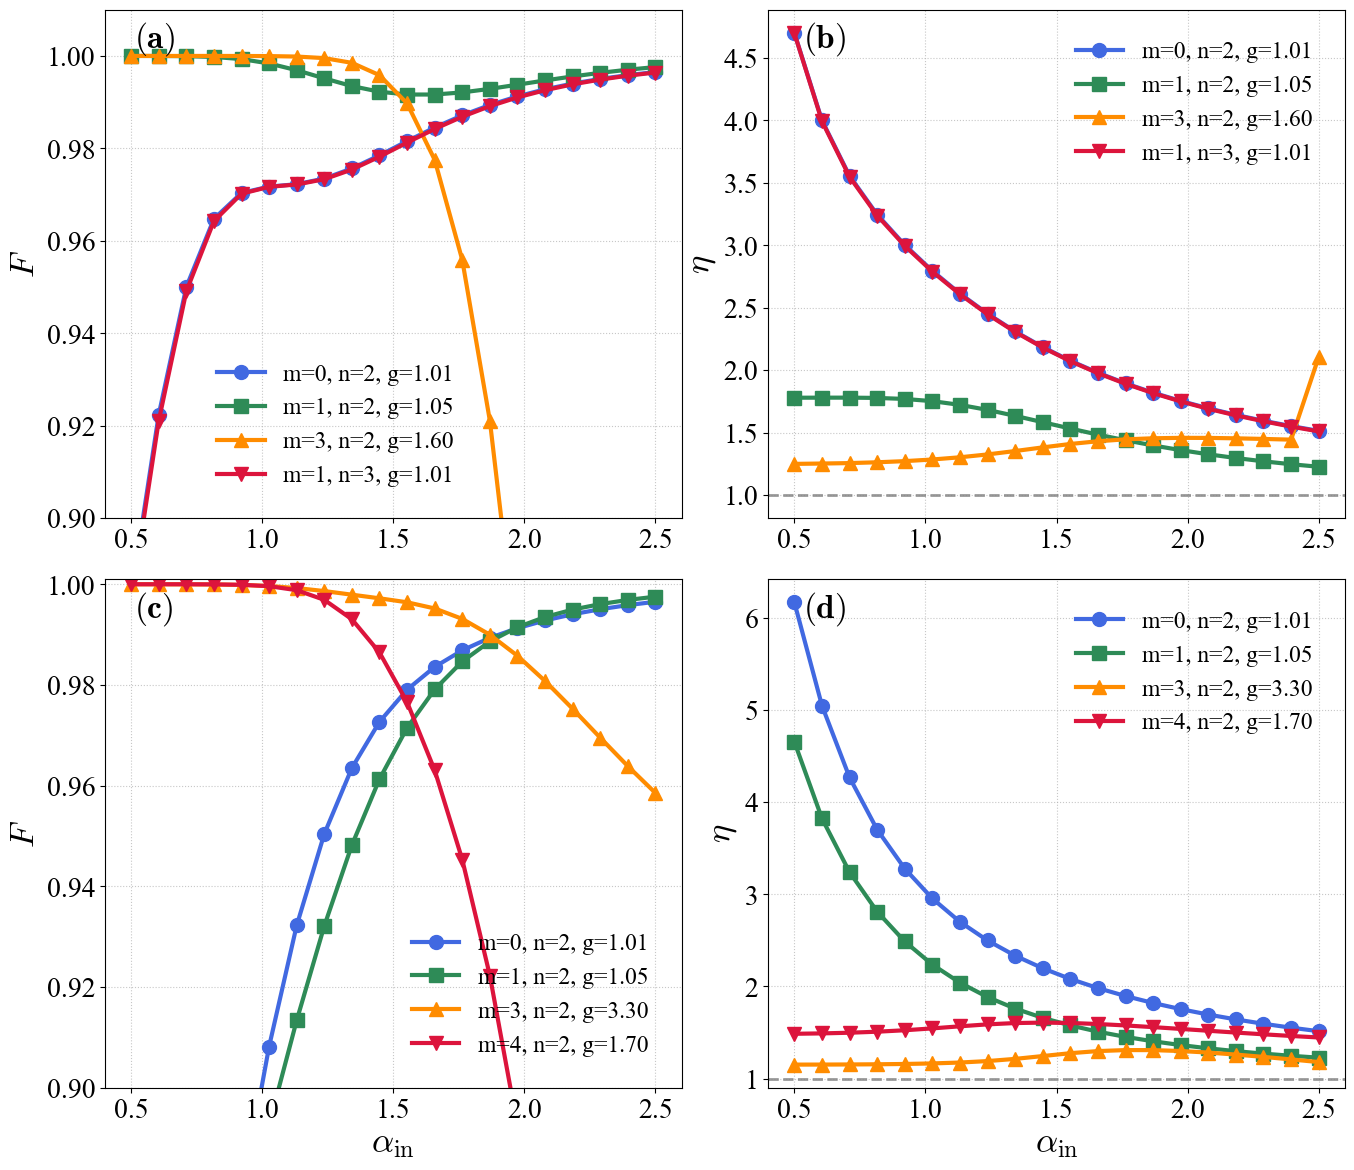

In [5]:
import numpy as np
import math
import scipy.linalg as la
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed
import time

# ============================================================
#  全局尺寸及字号设置 (统一大字号参数)
# ============================================================
FIG_SIZE = (16, 14)             # 画布整体物理尺寸 (宽, 高)
LABEL_SIZE = 25                 # 坐标轴标签大小
TICK_SIZE = 20                  # 坐标轴数字刻度大小
SUBPLOT_LABEL_SIZE = 24         # (a)(b)(c)(d) 角标字体大小
CASE_LABEL_SIZE = 17            # 图例 (m=, n=, g=) 文本大小

# ============================================================
#  图表样式配置
# ============================================================
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用全局参数
# ============================================================
N_DIM              = 60
ALPHA_IN_MIN       = 0.5
ALPHA_IN_MAX       = 2.5
ALPHA_IN_NPTS      = 20
RESTART_SEEDS      = [42, 123, 7]

DE_MAXITER         = 100
DE_POPSIZE         = 15
N_WORKERS          = -1        # 火力全开

# ============================================================
#  定义分组 Case
# ============================================================

# Even 输入组 (将绘制在图 a 和图 b)
cases_even = [
    {'label': 'm=0, n=2, g=1.01', 'm': 0, 'n': 2, 'g': 1.01, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=1, n=2, g=1.05', 'm': 1, 'n': 2, 'g': 1.05, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=3, n=2, g=1.60', 'm': 3, 'n': 2, 'g': 1.60, 'in_cat': 'even', 'at_offset': 4.0},
    {'label': 'm=1, n=3, g=1.01', 'm': 1, 'n': 3, 'g': 1.01, 'in_cat': 'even', 'at_offset': 4.0}  
]

# Odd 输入组 (将绘制在图 c 和图 d)
cases_odd = [
    {'label': 'm=0, n=2, g=1.01', 'm': 0, 'n': 2, 'g': 1.01, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=1, n=2, g=1.05', 'm': 1, 'n': 2, 'g': 1.05, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=3, n=2, g=3.30', 'm': 3, 'n': 2, 'g': 3.30, 'in_cat': 'odd', 'at_offset': 4.0},
    {'label': 'm=4, n=2, g=1.70', 'm': 4, 'n': 2, 'g': 1.70, 'in_cat': 'odd', 'at_offset': 4.0}
]

# 整合调度字典
all_case_groups = {
    'even_group': cases_even,
    'odd_group': cases_odd
}

# ============================================================
#  纯 Numpy 极速量子态生成引擎
# ============================================================
def get_coherent_np(dim, alpha):
    vec = np.zeros(dim, dtype=complex)
    vec[0] = 1.0
    for i in range(1, dim):
        vec[i] = vec[i-1] * alpha / math.sqrt(i)
    vec *= math.exp(-0.5 * alpha**2)
    return vec

def get_cat_state_np(dim, alpha, cat_type):
    ap = get_coherent_np(dim, alpha)
    am = get_coherent_np(dim, -alpha)
    vec = ap + am if cat_type == "even" else ap - am
    norm = np.linalg.norm(vec)
    return vec / norm if norm > 1e-15 else vec

def generate_catalyzed_state_np(m, n, g, phi_in, dim):
    if g <= 1.0: return None
    
    G = np.sqrt(1 - 1 / (g**2))
    a_op = np.diag(np.sqrt(np.arange(1, dim)), k=1)
    adag_op = a_op.T
    g_diag = g ** (-np.arange(dim, dtype=float))
    
    psi_out = np.zeros(dim, dtype=complex)
    fact_n, fact_m = math.factorial(n), math.factorial(m)
    
    for k in range(m + 1):
        if n - m + k < 0: continue
        
        num = ((-1)**(n - m + k)) * (G**(n - m + 2 * k)) * math.sqrt(fact_n * fact_m)
        den = (g**(m - k + 1)) * math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = num / den
        
        term = phi_in.copy()
        for _ in range(k): term = a_op @ term
        term = g_diag * term
        for _ in range(n - m + k): term = adag_op @ term
        
        psi_out += coef * term
        
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else None

# ============================================================
#  针对单一 alpha_in 的并行优化逻辑
# ============================================================
def optimize_one(alpha_in, case, N_dim, restart_seeds, maxiter, popsize):
    m_val = case['m']
    n_val = case['n']
    g_val = case['g']
    in_cat = case['in_cat']
    
    if abs(n_val - m_val) % 2 != 0:
        tgt_cat = "odd" if in_cat == "even" else "even"
    else:
        tgt_cat = in_cat
        
    phi_in = get_cat_state_np(N_dim, alpha_in, in_cat)
    psi_out = generate_catalyzed_state_np(m_val, n_val, g_val, phi_in, N_dim)
    if psi_out is None:
        return float(alpha_in), 0.0, float(alpha_in), 0.0
        
    a_op = np.diag(np.sqrt(np.arange(1, N_dim)), k=1)
    S_gen = 0.5 * (a_op @ a_op - a_op.T @ a_op.T)

    def cost(x):
        alpha_target, r_val = x
        try:
            cat_tgt = get_cat_state_np(N_dim, alpha_target, tgt_cat)
            psi_tgt = la.expm(r_val * S_gen) @ cat_tgt
            psi_tgt /= np.linalg.norm(psi_tgt)
            return -abs(np.vdot(psi_out, psi_tgt))**2
        except Exception:
            return 1.0

    bounds = [(max(0.1, alpha_in * 0.5), alpha_in + case['at_offset']), (-1.5, 1.5)]
    
    best_F = -1.0
    best_x = None
    
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds, strategy='best1bin',
            maxiter=maxiter, popsize=popsize,
            seed=seed, tol=1e-6, disp=False
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    return float(alpha_in), best_F, float(best_x[0]), float(best_x[1])

# ============================================================
#  主程序调度与绘图
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    start_time = time.time()
    
    print(f"🚀 启动精简版并行架构: 计算 Even 和 Odd 分组数据")
    
    all_results = {'even_group': {}, 'odd_group': {}}

    for group_key, cases_list in all_case_groups.items():
        print(f"\n================ 正在计算组别: {group_key} ================")
        for case in cases_list:
            label = case['label']
            print(f"-> 测算 Case: {label} [Input: {case['in_cat'].capitalize()}]")

            raw = Parallel(n_jobs=N_WORKERS, backend='loky')(
                delayed(optimize_one)(ai, case, N_DIM, RESTART_SEEDS, DE_MAXITER, DE_POPSIZE) 
                for ai in alpha_in_arr
            )

            raw.sort(key=lambda r: r[0])
            all_results[group_key][label] = raw

    print(f"\n✅ 模拟计算完成！总耗时: {time.time() - start_time:.2f} 秒")

    # ========================================================
    #  精美四宫格绘制 (2x2 布局)
    # ========================================================
    fig, axs = plt.subplots(2, 2, figsize=FIG_SIZE)
    fig.subplots_adjust(wspace=0.15, hspace=0.12) 

    ax_a = axs[0, 0] # 左上: (a) Even 保真度
    ax_b = axs[0, 1] # 右上: (b) Even 放大率
    ax_c = axs[1, 0] # 左下: (c) Odd 保真度
    ax_d = axs[1, 1] # 右下: (d) Odd 放大率

    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']
    
    plot_kwargs = dict(lw=3, ms=10)

    # --- 行 1：绘制 Even 组的保真度 (a) 和放大倍数 (b) ---
    for (label, data), color, marker in zip(all_results['even_group'].items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax_a.plot(alpha_vals, fids, marker=marker, color=color, label=label, **plot_kwargs)
        ax_b.plot(alpha_vals, amps, marker=marker, color=color, label=label, **plot_kwargs)

    # 样式配置 (a) - Even 保真度
    ax_a.set_ylabel(r'$F$', fontsize=LABEL_SIZE)
    ax_a.text(0.05, 0.98, r'$\mathbf{(a)}$', transform=ax_a.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_a.set_ylim(0.9, 1.01)
    ax_a.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_a.grid(True, ls=':', alpha=0.7)
    # 🌟 修改点：图 (a) 图例放置于右下角并向内微调
    ax_a.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='lower center', bbox_to_anchor=(0.4, 0.02))

    # 样式配置 (b) - Even 放大率
    ax_b.axhline(1.0, color='grey', ls='--', lw=2, alpha=0.8)
    ax_b.set_ylabel(r'$\eta$', fontsize=LABEL_SIZE)
    ax_b.text(0.06, 0.98, r'$\mathbf{(b)}$', transform=ax_b.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_b.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_b.grid(True, ls=':', alpha=0.7)
    # 🌟 修改点：图 (b) 图例放置于右上角并向内微调
    ax_b.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='upper right', bbox_to_anchor=(0.98, 0.98))


    # --- 行 2：绘制 Odd 组的保真度 (c) 和放大倍数 (d) ---
    for (label, data), color, marker in zip(all_results['odd_group'].items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax_c.plot(alpha_vals, fids, marker=marker, color=color, label=label, **plot_kwargs)
        ax_d.plot(alpha_vals, amps, marker=marker, color=color, label=label, **plot_kwargs)

    # 样式配置 (c) - Odd 保真度
    ax_c.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=LABEL_SIZE)
    ax_c.set_ylabel(r'$F$', fontsize=LABEL_SIZE)
    ax_c.text(0.05, 0.98, r'$\mathbf{(c)}$', transform=ax_c.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_c.set_ylim(0.9, 1.001)
    ax_c.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_c.grid(True, ls=':', alpha=0.7)
    # 🌟 修改点：图 (c) 图例放置于右下角并向内微调
    ax_c.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='lower right', bbox_to_anchor=(0.98, 0.02))

    # 样式配置 (d) - Odd 放大率
    ax_d.axhline(1.0, color='grey', ls='--', lw=2, alpha=0.8)
    ax_d.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=LABEL_SIZE)
    ax_d.set_ylabel(r'$\eta$', fontsize=LABEL_SIZE)
    ax_d.text(0.06, 0.98, r'$\mathbf{(d)}$', transform=ax_d.transAxes, fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left')
    ax_d.tick_params(axis='both', labelsize=TICK_SIZE)
    ax_d.grid(True, ls=':', alpha=0.7)
    # 🌟 修改点：图 (d) 图例放置于右上角并向内微调
    ax_d.legend(fontsize=CASE_LABEL_SIZE, frameon=False, loc='upper right', bbox_to_anchor=(0.98, 0.98))
    
    plt.savefig('catalysis_4grid_clean_labels.png', bbox_inches='tight', dpi=200)
    plt.show()

if __name__ == '__main__':
    main()